# 📈 Stock Price Prediction using Deep Learning

## Objective
Dự án này xây dựng và so sánh 3 mô hình dự đoán giá cổ phiếu:
- **LSTM** (Long Short-Term Memory)
- **GRU** (Gated Recurrent Unit)
- **Linear Regression** (baseline)

## Dataset
Dữ liệu từ Yahoo Finance API, tập trung vào các mã: `FPT.VN`, `VNM.VN`, `HPG.VN`

## Tech Stack
`Python` · `TensorFlow/Keras` · `yfinance` · `scikit-learn` · `matplotlib`

---


## Section 1 — Import Libraries

In [1]:
import sys
import os
import warnings
warnings.filterwarnings("ignore")

# Thêm src/ vào path để import các module
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import yfinance as yf

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print(f"TensorFlow version: {tf.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# Style cho plot đẹp hơn
plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams["figure.dpi"] = 100


TensorFlow version: 2.21.0
NumPy version: 2.4.6
Pandas version: 3.0.3


## Section 2 — Configuration

In [2]:
# ─── Chỉnh tại đây để thay đổi stock / thời gian ───
TICKER     = "FPT.VN"
START_DATE = "2020-01-01"
END_DATE   = "2026-01-01"
SEQ_LENGTH = 20     # số ngày look-back
TRAIN_RATIO = 0.8   # 80% train, 20% test
EPOCHS      = 150
BATCH_SIZE  = 16

print(f"Config: {TICKER} | {START_DATE} → {END_DATE}")
print(f"Sequence length: {SEQ_LENGTH} days | Train ratio: {TRAIN_RATIO}")


Config: FPT.VN | 2020-01-01 → 2026-01-01
Sequence length: 20 days | Train ratio: 0.8


## Section 3 — Load Data

Tải dữ liệu từ Yahoo Finance. Sử dụng hàm từ `src/data_loader.py`.

> **Note:** Cổ phiếu Việt Nam dùng suffix `.VN` (e.g. `FPT.VN`).


In [3]:
from data_loader import load_stock_data, save_raw_data

# Tải và lưu dữ liệu
df = load_stock_data(TICKER, START_DATE, END_DATE)
save_raw_data(df, TICKER, save_dir="../data/raw")

# Preview
print(f"\nShape: {df.shape}")
print(f"Date range: {df.index[0].date()} → {df.index[-1].date()}")
print(f"Columns: {list(df.columns)}")
df.head(10)


[DataLoader] Downloading FPT.VN from 2020-01-01 to 2026-01-01 ...
[DataLoader] Downloaded 1565 rows. Columns: ['Close', 'High', 'Low', 'Open', 'Volume']
[DataLoader] Saved raw data → ../data/raw\FPT_VN_raw.csv

Shape: (1565, 5)
Date range: 2020-01-01 → 2025-12-31
Columns: ['Close', 'High', 'Low', 'Open', 'Volume']


Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-01,20674.765625,20674.765625,20674.765625,20674.765625,0
2020-01-02,20781.148438,20923.000125,20568.372579,20674.761344,2164349
2020-01-03,20426.521484,20958.463654,20355.597311,20887.537809,4942821
2020-01-06,20213.748047,20426.523937,20142.822193,20249.210974,2634861
2020-01-07,20603.835938,20603.835938,20213.745462,20320.134229,2020786
2020-01-08,20142.824219,20461.988922,20142.824219,20391.064733,4379022
2020-01-09,20426.521484,20461.984407,20249.208542,20320.134388,2334099
2020-01-10,20391.060547,20497.447645,20249.208854,20391.060547,2458642
2020-01-13,20249.208984,20426.521930,20213.746061,20355.597755,1898946


In [4]:
# Thống kê cơ bản
df["Close"].describe()


count      1565.000000
mean      61646.023418
std       31759.038213
min       14326.936523
25%       42380.015625
50%       51063.941406
75%       93232.289062
max      129855.726562
Name: Close, dtype: float64

## Section 4 — Exploratory Data Analysis (EDA)

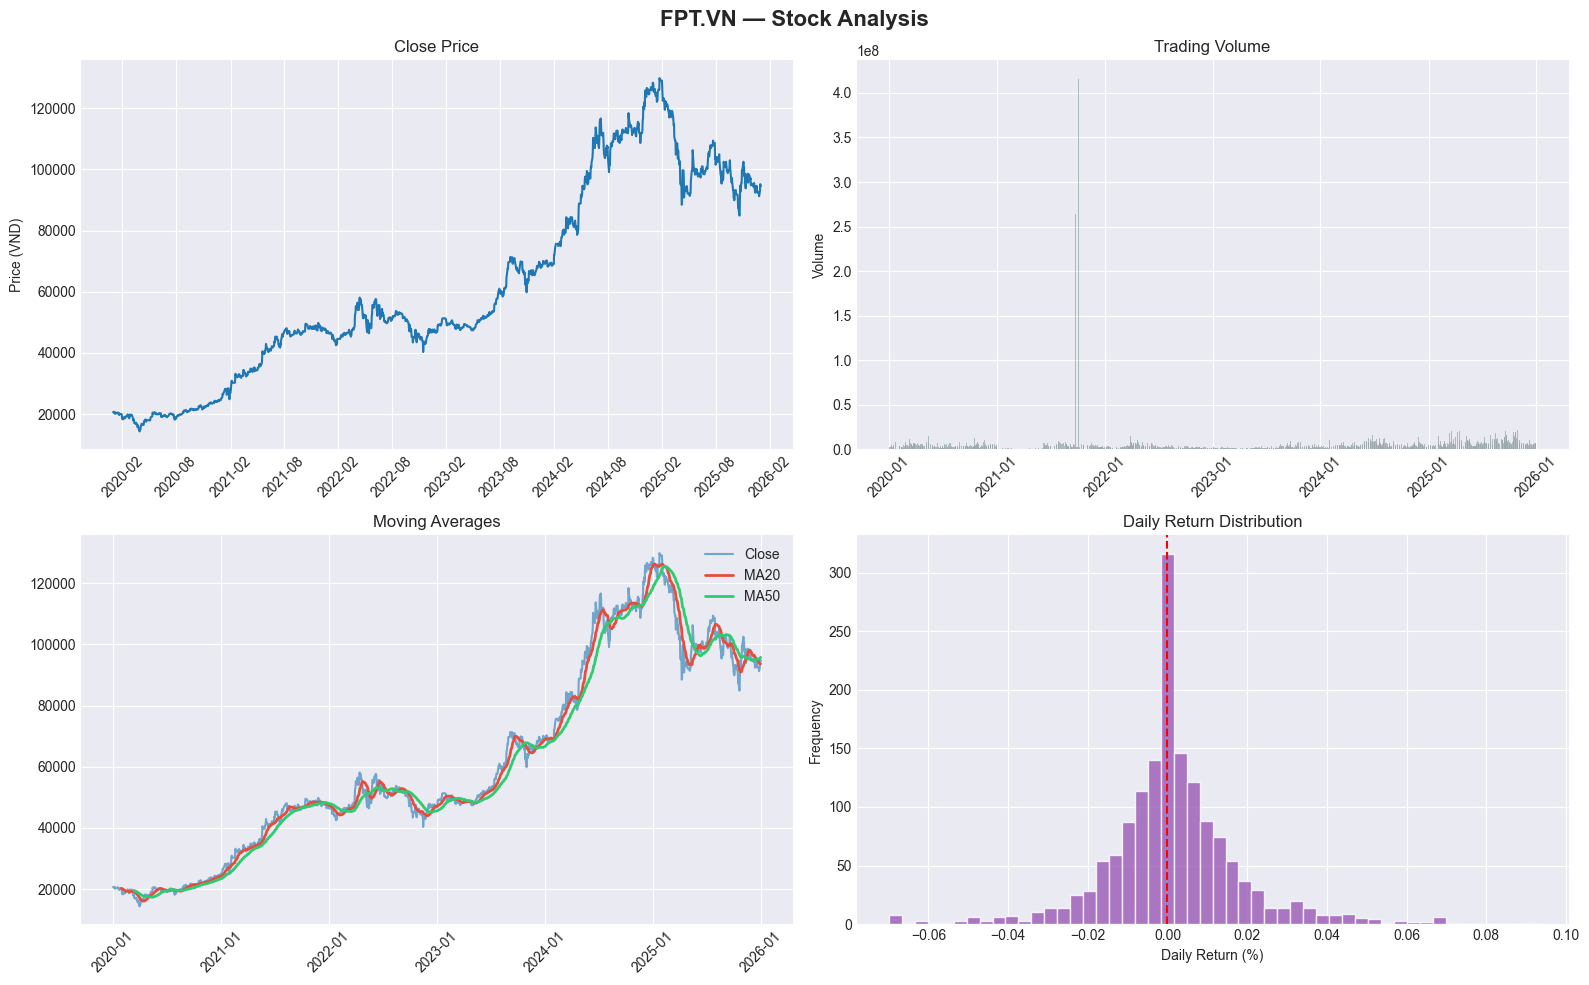

EDA plot saved to reports/


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(f"{TICKER} — Stock Analysis", fontsize=16, fontweight="bold")

# Plot 1: Close price
ax1 = axes[0, 0]
ax1.plot(df.index, df["Close"], color="#1f77b4", linewidth=1.5)
ax1.set_title("Close Price")
ax1.set_ylabel("Price (VND)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45)

# Plot 2: Volume
ax2 = axes[0, 1]
ax2.bar(df.index, df["Volume"], color="#95a5a6", alpha=0.7, width=2)
ax2.set_title("Trading Volume")
ax2.set_ylabel("Volume")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)

# Plot 3: 20-day & 50-day Moving Average
ax3 = axes[1, 0]
df["MA20"] = df["Close"].rolling(20).mean()
df["MA50"] = df["Close"].rolling(50).mean()
ax3.plot(df.index, df["Close"], label="Close",  color="#1f77b4", alpha=0.6)
ax3.plot(df.index, df["MA20"],  label="MA20",   color="#e74c3c", linewidth=2)
ax3.plot(df.index, df["MA50"],  label="MA50",   color="#2ecc71", linewidth=2)
ax3.set_title("Moving Averages")
ax3.legend()
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45)

# Plot 4: Daily return distribution
ax4 = axes[1, 1]
daily_return = df["Close"].pct_change().dropna()
ax4.hist(daily_return, bins=50, color="#9b59b6", edgecolor="white", alpha=0.8)
ax4.set_title("Daily Return Distribution")
ax4.set_xlabel("Daily Return (%)")
ax4.set_ylabel("Frequency")
ax4.axvline(0, color="red", linestyle="--")

plt.tight_layout()
plt.savefig(f"../reports/{TICKER}_eda.png", dpi=150, bbox_inches="tight")
plt.show()
print("EDA plot saved to reports/")


## Section 5 — Preprocessing

Steps:
1. Lấy cột **Close price**
2. **Normalize** về [0, 1] dùng MinMaxScaler
3. **Train/test split** theo thời gian (không shuffle)
4. Tạo **sequences** (X, y) với look-back window = 60 ngày


In [6]:
from preprocessing import prepare_data_for_training

data = prepare_data_for_training(df, seq_length=SEQ_LENGTH, train_ratio=TRAIN_RATIO)

X_train      = data["X_train"]
y_train      = data["y_train"]
X_test       = data["X_test"]
y_test       = data["y_test"]
X_train_lin  = data["X_train_lin"]
y_train_lin  = data["y_train_lin"]
X_test_lin   = data["X_test_lin"]
y_test_lin   = data["y_test_lin"]
scaler       = data["scaler"]

print(f"LSTM/GRU — X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"LSTM/GRU — X_test:  {X_test.shape}  | y_test:  {y_test.shape}")
print(f"Linear   — X_train: {X_train_lin.shape}")
print(f"Linear   — X_test:  {X_test_lin.shape}")


[Preprocessing] Feature engineering done. Rows after dropna: 1516
[Preprocessing] Train size: 1212 | Test size: 304
[Preprocessing] Created sequences: X=(1192, 20, 16), y=(1192,)
[Preprocessing] Created sequences: X=(304, 20, 16), y=(304,)
LSTM/GRU — X_train: (1192, 20, 16) | y_train: (1192,)
LSTM/GRU — X_test:  (304, 20, 16)  | y_test:  (304,)
Linear   — X_train: (1192, 320)
Linear   — X_test:  (304, 320)


In [7]:
# Visualize normalized data + train/test split
close_prices = df["Close"].values
split_idx = int(len(close_prices) * TRAIN_RATIO)

plt.figure(figsize=(13, 4))
plt.plot(df.index[:split_idx], close_prices[:split_idx], 
         label="Train", color="#1f77b4", linewidth=1.5)
plt.plot(df.index[split_idx:], close_prices[split_idx:], 
         label="Test", color="#e74c3c", linewidth=1.5)
plt.axvline(df.index[split_idx], color="gray", linestyle="--", alpha=0.8, label="Split")
plt.title(f"{TICKER} — Train / Test Split (80/20)")
plt.ylabel("Price (VND)")
plt.legend()
plt.tight_layout()
plt.savefig(f"../reports/{TICKER}_train_test_split.png", dpi=150, bbox_inches="tight")
plt.show()


## Section 6 — Train LSTM

**LSTM (Long Short-Term Memory)** phù hợp với chuỗi thời gian nhờ cơ chế gates kiểm soát thông tin.

Architecture:
- LSTM(64) → Dropout(0.2) → LSTM(32) → Dropout(0.2) → Dense(16) → Dense(1)


In [8]:
from train_lstm import train_lstm
from utils import save_keras_model

lstm_model, lstm_history = train_lstm(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

save_keras_model(lstm_model, "../models/lstm/lstm_model.keras")
print("LSTM model saved.")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,697 (131.63 KB)

 Trainable params: 33,697 (131.63 KB)

 Non-trainable params: 0 (0.00 B)


[LSTM] Training on 1192 samples ...
Epoch 1/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0036 - val_loss: 0.0358 - learning_rate: 3.0000e-04
Epoch 2/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0112 - val_loss: 0.0222 - learning_rate: 3.0000e-04
Epoch 3/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0021 - val_loss: 0.0186 - learning_rate: 3.0000e-04
Epoch 4/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0018 - val_loss: 0.0232 - learning_rate: 3.0000e-04
Epoch 5/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0017 - val_loss: 0.0245 - learning_rate: 3.0000e-04
Epoch 6/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0020 - val_loss: 0.0177 - learning_rate: 3.0000e-04
Epoch 7/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0014 - val_loss: 0.0298 - learning_rate: 3.0000e-04
Epoch 8/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0011 - val_loss: 0.0279 - learning_rate: 3.0000e-04
Epoch 9/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss:

In [9]:
# Loss curve
plt.figure(figsize=(10, 4))
plt.plot(lstm_history.history["loss"],     label="Train Loss", color="#e74c3c")
plt.plot(lstm_history.history["val_loss"], label="Val Loss",   color="#3498db", linestyle="--")
plt.title("LSTM — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/lstm_loss.png", dpi=150, bbox_inches="tight")
plt.show()


## Section 7 — Train GRU

**GRU (Gated Recurrent Unit)** tương tự LSTM nhưng đơn giản hơn (ít tham số hơn), thường train nhanh hơn.


In [10]:
from train_gru import train_gru

gru_model, gru_history = train_gru(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

save_keras_model(gru_model, "../models/gru/gru_model.keras")
print("GRU model saved.")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 20, 64)         │        15,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,697 (100.38 KB)

 Trainable params: 25,697 (100.38 KB)

 Non-trainable params: 0 (0.00 B)


[GRU] Training on 1192 samples ...
Epoch 1/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0063 - val_loss: 0.0176 - learning_rate: 3.0000e-04
Epoch 2/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0074 - val_loss: 0.0052 - learning_rate: 3.0000e-04
Epoch 3/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0028 - val_loss: 0.0049 - learning_rate: 3.0000e-04
Epoch 4/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0031 - val_loss: 0.0049 - learning_rate: 3.0000e-04
Epoch 5/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0021 - val_loss: 0.0022 - learning_rate: 3.0000e-04
Epoch 6/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0023 - val_loss: 0.0018 - learning_rate: 3.0000e-04
Epoch 7/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0018 - val_loss: 0.0018 - learning_rate: 3.0000e-04
Epoch 8/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0017 - val_loss: 0.0028 - learning_rate: 3.0000e-04
Epoch 9/150
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(gru_history.history["loss"],     label="Train Loss", color="#e74c3c")
plt.plot(gru_history.history["val_loss"], label="Val Loss",   color="#2ecc71", linestyle="--")
plt.title("GRU — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/gru_loss.png", dpi=150, bbox_inches="tight")
plt.show()


## Section 8 — Train Linear Regression (Baseline)

Model đơn giản nhất để làm **baseline** so sánh — nếu LSTM/GRU không beat được Linear thì cần xem lại.


In [12]:
from train_linear import train_linear
from utils import save_sklearn_model

lin_model = train_linear(X_train_lin, y_train_lin)
save_sklearn_model(lin_model, "../models/linear/linear.pkl")
print("Linear model saved.")



[Linear] Training on 1192 samples ...
[Linear] Training done.
[Utils] Sklearn model saved → ../models/linear/linear.pkl
Linear model saved.


## Section 9 — Generate Predictions

In [13]:
from predict import predict_keras, predict_linear
from evaluate import inverse_scale

# Raw predictions (normalized scale)
lstm_preds_scaled  = predict_keras(lstm_model, X_test)
gru_preds_scaled   = predict_keras(gru_model,  X_test)
lin_preds_scaled   = predict_linear(lin_model, X_test_lin)

# Inverse transform → original price
y_true     = inverse_scale(y_test,            scaler)
lstm_preds = inverse_scale(lstm_preds_scaled, scaler)
gru_preds  = inverse_scale(gru_preds_scaled,  scaler)
lin_preds  = inverse_scale(lin_preds_scaled,  scaler)

print(f"Predictions generated. Sample size: {len(y_true)}")
print(f"Price range — Actual:  {y_true.min():.0f} → {y_true.max():.0f}")
print(f"Price range — LSTM:    {lstm_preds.min():.0f} → {lstm_preds.max():.0f}")
print(f"Price range — GRU:     {gru_preds.min():.0f} → {gru_preds.max():.0f}")
print(f"Price range — Linear:  {lin_preds.min():.0f} → {lin_preds.max():.0f}")


Predictions generated. Sample size: 304
Price range — Actual:  84934 → 129856
Price range — LSTM:    79069 → 96214
Price range — GRU:     88941 → 120243
Price range — Linear:  85675 → 130841


## Section 10 — Evaluation & Model Comparison

Metrics:
- **RMSE** (Root Mean Squared Error) — penalizes large errors, lower is better
- **MAE** (Mean Absolute Error) — average absolute error
- **MAPE** (Mean Absolute Percentage Error) — error in %


In [14]:
from evaluate import calculate_metrics, compare_models, print_comparison

results = {
    "LSTM":   calculate_metrics(y_true, lstm_preds),
    "GRU":    calculate_metrics(y_true, gru_preds),
    "Linear": calculate_metrics(y_true, lin_preds),
}

comparison_df = compare_models(results)
print_comparison(comparison_df)

# Save
comparison_df.to_csv("../reports/model_comparison.csv", index=False)
comparison_df



         MODEL COMPARISON RESULTS
    Model        RMSE         MAE  MAPE (%)
1  Linear   2281.5666   1714.5083    1.6641
2     GRU   5123.7164   3918.9203    3.5451
3    LSTM  19975.8685  18343.7763   16.8264
Best model: Linear



,Model,RMSE,MAE,MAPE (%)
1,Linear,2281.5666,1714.5083,1.6641
2,GRU,5123.7164,3918.9203,3.5451
3,LSTM,19975.8685,18343.7763,16.8264


In [15]:
# ── Prediction Chart ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(y_true, label="Actual", color="black", linewidth=2, zorder=5)
ax.plot(lstm_preds, label=f"LSTM  (RMSE={results['LSTM']['rmse']:.2f})",
        color="#e74c3c", linestyle="-", linewidth=1.5, alpha=0.9)
ax.plot(gru_preds,  label=f"GRU   (RMSE={results['GRU']['rmse']:.2f})",
        color="#2ecc71", linestyle="--", linewidth=1.5, alpha=0.9)
ax.plot(lin_preds,  label=f"Linear (RMSE={results['Linear']['rmse']:.2f})",
        color="#3498db", linestyle="-.", linewidth=1.5, alpha=0.9)

ax.set_title(f"{TICKER} — Model Predictions vs Actual Prices", fontsize=14, fontweight="bold")
ax.set_xlabel("Time Steps (Test Period)")
ax.set_ylabel("Price (VND)")
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(f"../reports/{TICKER}_predictions.png", dpi=150, bbox_inches="tight")
plt.show()


In [16]:
# ── RMSE Bar Chart ────────────────────────────────────────────────────────
from utils import plot_comparison_bar
plot_comparison_bar(comparison_df, save_path="../reports/model_comparison_bar.png")


[Utils] Plot saved → ../reports/model_comparison_bar.png


In [17]:
# ── Loss curves side-by-side ─────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(lstm_history.history["loss"],     label="Train", color="#e74c3c")
ax1.plot(lstm_history.history["val_loss"], label="Val",   color="#e74c3c", linestyle="--")
ax1.set_title("LSTM — Loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("MSE Loss"); ax1.legend()

ax2.plot(gru_history.history["loss"],     label="Train", color="#2ecc71")
ax2.plot(gru_history.history["val_loss"], label="Val",   color="#2ecc71", linestyle="--")
ax2.set_title("GRU — Loss")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("MSE Loss"); ax2.legend()

plt.suptitle("Training Loss Curves", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/training_loss_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## Section 11 — Multi-Stock Quick Compare

Chạy nhanh pipeline cho 3 mã cổ phiếu, so sánh RMSE của LSTM.


In [18]:
TICKERS = ["FPT.VN", "VNM.VN", "HPG.VN"]
multi_results = {}

for t in TICKERS:
    try:
        print(f"\n{'─'*40}")
        print(f"Processing: {t}")
        _df = load_stock_data(t, START_DATE, END_DATE)
        _data = prepare_data_for_training(_df, seq_length=SEQ_LENGTH)
        
        _lstm, _ = train_lstm(_data["X_train"], _data["y_train"], epochs=20, batch_size=32)
        _preds_sc = predict_keras(_lstm, _data["X_test"])
        _y_true   = inverse_scale(_data["y_test"],   _data["scaler"])
        _y_pred   = inverse_scale(_preds_sc,          _data["scaler"])
        
        m = calculate_metrics(_y_true, _y_pred)
        multi_results[t] = m
        print(f"  → RMSE: {m['rmse']:.2f} | MAE: {m['mae']:.2f} | MAPE: {m['mape']:.2f}%")
    except Exception as e:
        print(f"  [ERROR] {t}: {e}")

print("\n=== Multi-Stock LSTM RMSE Summary ===")
for t, m in multi_results.items():
    print(f"  {t:12s}  RMSE={m['rmse']:.2f}  MAE={m['mae']:.2f}  MAPE={m['mape']:.2f}%")



────────────────────────────────────────
Processing: FPT.VN
[DataLoader] Downloading FPT.VN from 2020-01-01 to 2026-01-01 ...
[DataLoader] Downloaded 1565 rows. Columns: ['Close', 'High', 'Low', 'Open', 'Volume']
[Preprocessing] Feature engineering done. Rows after dropna: 1546
[Preprocessing] Train size: 1236 | Test size: 310
[Preprocessing] Created sequences: X=(1216, 20, 16), y=(1216,)
[Preprocessing] Created sequences: X=(310, 20, 16), y=(310,)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 20, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,697 (131.63 KB)

 Trainable params: 33,697 (131.63 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 20, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,697 (131.63 KB)

 Trainable params: 33,697 (131.63 KB)

 Non-trainable params: 0 (0.00 B)


[LSTM] Training on 1216 samples ...
Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.1172 - val_loss: 0.0031 - learning_rate: 3.0000e-04
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0204 - val_loss: 0.0019 - learning_rate: 3.0000e-04
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0147 - val_loss: 0.0022 - learning_rate: 3.0000e-04
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0130 - val_loss: 0.0011 - learning_rate: 3.0000e-04
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0117 - val_loss: 0.0011 - learning_rate: 3.0000e-04
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0080 - val_loss: 9.4221e-04 - learning_rate: 3.0000e-04
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0076 - val_loss: 0.0012 - learning_rate: 3.0000e-04
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0061 - val_loss: 0.0015 - learning_rate: 3.0000e-04
Epoch 9/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0

## Section 12 — Save / Load Model Demo

In [19]:
from utils import load_keras_model, load_sklearn_model

# Load models từ disk
loaded_lstm   = load_keras_model("../models/lstm/lstm_model.keras")
loaded_gru    = load_keras_model("../models/gru/gru_model.keras")
loaded_linear = load_sklearn_model("../models/linear/linear.pkl")

# Verify bằng cách predict lại
verify_preds = predict_keras(loaded_lstm, X_test[:5])
original_preds = predict_keras(lstm_model, X_test[:5])

print("\nVerification (first 5 predictions):")
print(f"  Original:  {original_preds}")
print(f"  Reloaded:  {verify_preds}")
match = np.allclose(verify_preds, original_preds, atol=1e-5)
print(f"  Match: {'✅ YES' if match else '❌ NO'}")


[Utils] Keras model loaded ← ../models/lstm/lstm_model.keras
[Utils] Keras model loaded ← ../models/gru/gru_model.keras
[Utils] Sklearn model loaded ← ../models/linear/linear.pkl

Verification (first 5 predictions):
  Original:  [0.7301397  0.7282558  0.7260676  0.72427887 0.72344005]
  Reloaded:  [0.7301397  0.7282558  0.7260676  0.72427887 0.72344005]
  Match: ✅ YES


## Section 13 — Conclusion

### Tóm tắt kết quả

| Model | Đặc điểm | Khi nào dùng |
|-------|----------|--------------|
| **LSTM** | Tốt nhất với long-term dependencies | Khi cần độ chính xác cao |
| **GRU** | Tương đương LSTM, train nhanh hơn | Khi cần trade-off speed/accuracy |
| **Linear** | Baseline đơn giản | Để so sánh chuẩn |

### Hạn chế
- Mô hình chỉ dùng **Close price** — có thể bổ sung Volume, Open, High, Low
- Chưa tích hợp **sentiment analysis** từ tin tức
- Stock market có tính **non-stationary** cao → accuracy bị giới hạn

### Future Work
- Thêm **Transformer/Attention** model
- Feature engineering: technical indicators (RSI, MACD, Bollinger Bands)
- Deploy lên Streamlit dashboard

---
*Generated by AI Stock Prediction Project*
